In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
file_path = "PhiUSIIL_Phishing_URL_Dataset.csv"
df_full = pd.read_csv(file_path, header=0)
df_full.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [45]:
#not sure if we need more stuff, can add later on
df = df_full[["URL", "label"]].copy()

print("\nShape:")
print(df.shape)
print("\nHead:")
print(df.head())
print("\nType:")
print(df.dtypes)


Shape:
(235795, 2)

Head:
                                  URL  label
0    https://www.southbankmosaics.com      1
1            https://www.uni-mainz.de      1
2      https://www.voicefmradio.co.uk      1
3         https://www.sfnmjournal.com      1
4  https://www.rewildingargentina.org      1

Type:
URL      object
label     int64
dtype: object


In [61]:
#check missing
print(df.isna().sum())

Missing URL      0
label    0
dtype: int64


In [36]:
#check empty and duplicates URLs
df["URL"] = df["URL"].astype(str).str.strip()

print("Empty URLs:", df["URL"].eq("").sum())
print("Unique URLs:", df["URL"].nunique())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate URLs:", df.duplicated(subset="URL").sum())

Empty URLs: 0
Unique URLs: 235370
Duplicate rows: 425
Duplicate URLs: 425


In [46]:
#see duplicates
duplicates = df[df.duplicated(subset="URL", keep=False)] \
                .sort_values("URL")

print(duplicates)

                                                      URL  label
219489              http://2f3a.reicrut-chat.workers.dev/      0
57609               http://2f3a.reicrut-chat.workers.dev/      0
227564                             http://34.149.138.117/      0
27166                              http://34.149.138.117/      0
147448  http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...      0
...                                                   ...    ...
218592               https://yahoo-109157.weeblysite.com/      0
14008                https://yasssouadjanclecles.web.app/      0
137897               https://yasssouadjanclecles.web.app/      0
207435    https://yellow-river-189b.lhziiz35.workers.dev/      0
235738    https://yellow-river-189b.lhziiz35.workers.dev/      0

[850 rows x 2 columns]


In [54]:
#check if any labels are diff for any duplicates
label_counts = duplicates.groupby("URL")["label"].nunique()

conflicting_urls = label_counts[label_counts > 1]

print("URLs with conflicting labels:", len(conflicting_urls))
print(conflicting_urls)

URLs with conflicting labels: 0
Series([], Name: label, dtype: int64)


In [51]:
#drop duplicates
df = df.drop_duplicates(subset = "URL", keep = "first").reset_index(drop = True)
print("Rows after removing duplicates:", len(df))
print("Duplicate URLs remaining:", df.duplicated(subset="URL").sum())

Rows after removing duplicates: 235370
Duplicate URLs remaining: 0


             Count  Percentage
label                         
Legitimate  134850   57.292773
Phishing    100520   42.707227


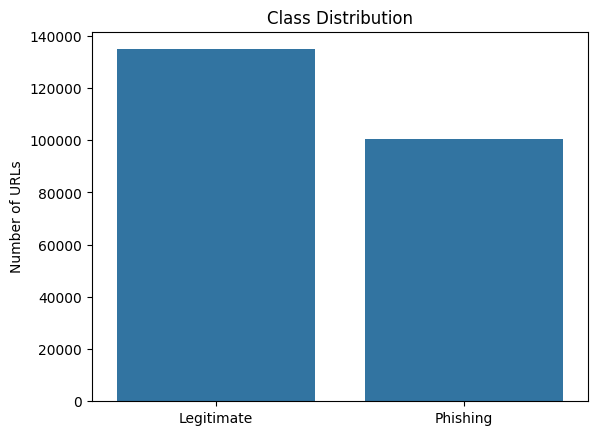

In [63]:
#check for class distributions (helps to explain metrics??)
class_counts = (
    df["label"]
    .value_counts()
    .rename(index={0: "Phishing", 1: "Legitimate"})
)

class_percent = (
    df["label"]
    .value_counts(normalize=True)
    .mul(100)
    .rename(index={0: "Phishing", 1: "Legitimate"})
)

print(pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percent
}))

sns.countplot(
    data=df.assign(
        Class=df["label"].map({0: "Phishing", 1: "Legitimate"})
    ),
    x="Class"
)
plt.title("Class Distribution")
plt.xlabel("")
plt.ylabel("Number of URLs")
plt.show()

In [ ]:
#do we parse URL into modifiable components?

In [64]:
#analyse URL (check original dataset idk what stuff to keep/throw yet)
#basic stuff (url length, digit count, letter count, special count -> eda by ratio? summary by class?
#url length distribution 
#character vocabulary
#URL component analysis

In [ ]:
#check for domain leakage before split (???)

In [60]:
#analyse what parts can be manipulated adverserially

In [ ]:
#see how edit budget affect URL length...